# Simulação de sistema de recomendação (com dados reduzidos via PCA)
___

### Importando bibliotecas/dados:

In [61]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

import time
from itertools import combinations

import matplotlib.pyplot as plt
import seaborn as sns

import random

In [62]:
df = pd.read_csv('../data/pca/df_pca_numerico.csv')
df_descritivo = pd.read_csv('../data/pca/df_pca_descritivo.csv')

In [63]:
cluster_cols = [
    c for c in [
        "cluster_pca_kmeans",
        "cluster_pca_gmm",
    ]
    if c in df.columns
]

y = df[cluster_cols].copy()

feature_cols = [c for c in df.columns if c not in cluster_cols]
X = df[feature_cols].to_numpy(dtype=float)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

df_scaled = pd.DataFrame(X_scaled, columns=feature_cols, index=df.index)
df_scaled

,popularity,duration_ms,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,mode
0,1.932530,0.000308,0.648376,-0.682910,-1.204468,0.338829,0.479250,-0.869304,-0.545775,0.709881,0.944713,-1.140340,0.224408,-1.314252
1,1.025884,-0.708542,-0.799051,-1.830529,-1.204468,-1.663314,-0.103475,1.765788,-0.545761,-0.597338,-0.759256,-1.487084,0.224408,0.760889
2,1.126623,-0.173196,-0.697279,-1.079714,-1.485576,-0.231521,-0.283447,-0.343941,-0.545778,-0.515955,-1.318370,-1.525556,0.224408,0.760889
3,1.831792,-0.250967,-1.669769,-2.244450,-1.485576,-1.907641,-0.452935,1.709647,-0.545562,-0.439658,-1.230890,1.979394,-1.986393,0.760889
4,2.385853,-0.277902,0.320443,-0.752934,-0.923359,-0.221404,-0.310530,0.421353,-0.545778,-0.689403,-1.139606,-0.075235,0.224408,0.760889
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86700,-0.686669,1.349979,-2.201246,-1.562103,-0.080032,-1.502593,-0.401390,0.926624,2.289501,-0.672109,-1.645852,0.125802,2.435208,0.760889
86701,-0.636300,1.349988,-2.189938,-2.021151,-1.485576,-1.870037,-0.419737,1.972624,2.436154,-0.576992,-1.641668,-1.229387,0.224408,-1.314252
86702,-0.636300,0.357112,0.382637,-1.196421,-1.485576,-0.453133,-0.403137,1.597364,-0.545778,-0.684317,1.051211,0.338045,0.224408,-1.314252
86703,0.320715,0.465788,0.145169,-0.507849,0.482186,-0.451988,-0.510596,0.161330,-0.545778,0.262273,-0.203945,0.457151,0.224408,0.760889


### Simulação de um usuário
___
O usuário começa com 5 músicas selecionadas para mitigar o _cold-start_, simulando técnicas que plataformas costumam utilizar para esse fim.

In [64]:
rng = np.random.default_rng(seed=42)
musicas_usuario = rng.choice(len(df_scaled), size=5, replace=False)
musicas_usuario

array([67103, 38052, 56753,  7738, 37544])

In [65]:
# Calculando o vetor médio do usuário:
vetor_usuario = X_scaled[musicas_usuario].mean(axis=0)
vetor_usuario


array([ 1.09640126,  0.04792745, -0.52087388, -0.31022508, -0.52980622,
        0.02712191, -0.3685407 , -0.22864429, -0.16120408, -0.58879294,
       -0.42454762, -0.05954706,  0.22440751, -0.06916738])

### TESTE INICIAL GLOBAL
___

In [66]:
X_scaled_np = df_scaled.to_numpy(dtype=float)
u_2d = np.asarray(vetor_usuario, dtype=float).reshape(1, -1)
excluded = set(int(i) for i in np.asarray(globals().get("user_seed_indices", [])).tolist())

t0 = time.perf_counter()

sims = cosine_similarity(u_2d, X_scaled_np)[0]
ranked_indices = np.argsort(sims)[::-1]
top10_global_idx = np.array([int(i) for i in ranked_indices if int(i) not in excluded][:10], dtype=int)
top10_global_scores = sims[top10_global_idx]

tempo_execucao = time.perf_counter() - t0

num_musicas_global = df_scaled.shape[0]

print("Top 10 índices:", top10_global_idx.tolist())
print("Top 10 similaridades:", np.round(top10_global_scores, 4).tolist())
print(f"Tempo de execução: {tempo_execucao:.6f} s ({tempo_execucao * 1000:.2f} ms)")

Top 10 índices: [58, 31365, 37532, 29890, 27207, 85777, 47006, 2226, 2042, 64816]
Top 10 similaridades: [0.9011, 0.8872, 0.8858, 0.8854, 0.8841, 0.8782, 0.867, 0.8666, 0.8631, 0.8626]
Tempo de execução: 0.030645 s (30.64 ms)


### TESTE LOCAL (K-Means)
___


In [67]:
col_kmeans = "cluster_pca_kmeans"  # ajuste o nome se a coluna do K-Means tiver outro nome em `y`
labels_kmeans = y[col_kmeans].to_numpy()

# 1. Dicionário com os vetores médios (centroides) de cada cluster do K-Means em `df_scaled`
centroids_kmeans = {}
for c in np.sort(np.unique(labels_kmeans)):
    mask = labels_kmeans == c
    centroids_kmeans[int(c)] = df_scaled.loc[mask].mean(axis=0).to_numpy()

centroids_kmeans

{0: array([-0.19539623, -0.11275089, -0.71094558, -1.43476303, -0.09037819,
        -1.33037357, -0.27018186,  1.35241783,  0.58332569, -0.19024828,
        -0.73059892, -0.44795403, -0.50815797,  0.13125974]),
 1: array([ 0.17689396, -0.17523222,  0.64377088,  0.14512648,  0.02190149,
         0.264711  ,  0.16793897, -0.06149258, -0.4149876 , -0.02708054,
         0.69357886, -0.12642246,  0.16792558, -0.0008297 ]),
 2: array([-0.11950114,  0.3023462 , -0.4349975 ,  0.66738547,  0.02495498,
         0.44457118, -0.06259526, -0.72991232,  0.20531278,  0.15052099,
        -0.48988485,  0.43831144,  0.08034872, -0.07772234])}

In [68]:
u_2d = np.asarray(vetor_usuario, dtype=float).reshape(1, -1)

sim_kmeans = {}
for c, centroid in centroids_kmeans.items():
    c_2d = np.asarray(centroid, dtype=float).reshape(1, -1)
    sim_kmeans[c] = float(cosine_similarity(u_2d, c_2d)[0, 0])

# Ordena do maior para o menor score de similaridade
ranking_clusters = sorted(sim_kmeans.items(), key=lambda x: x[1], reverse=True)

for c, score in ranking_clusters:
    print(f"Cluster {c}: similaridade de cosseno = {score:.4f}")

best_cluster_kmeans = ranking_clusters[0][0]
print(f"\nCluster ideal (maior similaridade de cosseno): {best_cluster_kmeans}")

Cluster 0: similaridade de cosseno = 0.1395
Cluster 2: similaridade de cosseno = 0.0764
Cluster 1: similaridade de cosseno = -0.2228

Cluster ideal (maior similaridade de cosseno): 0


In [69]:
# 2. Filtra apenas os índices do dataset pertencentes ao melhor cluster
cluster_indices = np.flatnonzero(labels_kmeans == best_cluster_kmeans)
X_cluster = X_scaled_np[cluster_indices]

excluded = set(int(i) for i in np.asarray(globals().get("user_seed_indices", [])).tolist())

# 3. Mede o tempo de execução do Top 10 exclusivamente dentro do melhor cluster
t0 = time.perf_counter()

sims_local = cosine_similarity(u_2d, X_cluster)[0]
ranked_local_pos = np.argsort(sims_local)[::-1]

top10_local_idx = np.array(
    [int(cluster_indices[pos]) for pos in ranked_local_pos if int(cluster_indices[pos]) not in excluded][:10],
    dtype=int,
)
top10_local_scores_kmeans = sims_local[
    [int(np.flatnonzero(cluster_indices == idx)[0]) for idx in top10_local_idx]
]

tempo_execucao_local_kmeans = time.perf_counter() - t0

num_musicas_kmeans = len(cluster_indices)

print(f"Melhor cluster (K-Means): {best_cluster_kmeans} ({len(cluster_indices)} músicas)")
print("Top 10 índices (local):", top10_local_idx.tolist())
print("Top 10 similaridades (local):", np.round(top10_local_scores_kmeans, 4).tolist())
print('Média de similaridade (local): ', np.round(top10_local_scores_kmeans.mean(), 4))
print(f"Tempo de execução (local): {tempo_execucao_local_kmeans:.6f} s ({tempo_execucao_local_kmeans * 1000:.2f} ms)")

Melhor cluster (K-Means): 0 (17715 músicas)
Top 10 índices (local): [31043, 10194, 2472, 65135, 2010, 64990, 30999, 80241, 78444, 3306]
Top 10 similaridades (local): [0.8317, 0.8268, 0.812, 0.8118, 0.8104, 0.8104, 0.8076, 0.8033, 0.8012, 0.7988]
Média de similaridade (local):  0.8114
Tempo de execução (local): 0.009252 s (9.25 ms)


### TESTE LOCAL (GMM)
___

In [70]:
col_gmm = "cluster_pca_gmm" 
labels_gmm = y[col_gmm].to_numpy()

centroids_gmm = {}
for c in np.sort(np.unique(labels_gmm)):
    mask = labels_gmm == c
    centroids_gmm[int(c)] = df_scaled.loc[mask].mean(axis=0).to_numpy()

centroids_gmm

{0: array([ 0.03948644,  0.03034696,  0.18834639,  0.19469698,  0.20350879,
         0.17088195, -0.03219357, -0.22206022,  0.02408714, -0.04568008,
         0.03776529,  0.03316461,  0.22440751, -1.31425204]),
 1: array([ 0.12404105, -0.12000223,  0.13048288,  0.10145194, -0.08734817,
         0.26963727, -0.10750243, -0.04920234, -0.53948583,  0.03135382,
         0.26493748,  0.04504828,  0.22440751,  0.76088906]),
 2: array([-0.18328319, -0.19680487, -0.06269161,  0.077695  , -0.03850718,
        -0.04823071,  2.71798166,  0.37244604, -0.39426911,  0.90583454,
         0.01357365, -0.17236522, -0.74002734, -0.02381852]),
 3: array([-0.22457878,  0.19792565, -0.97531004, -1.02631136, -0.07172261,
        -1.09795124, -0.35939421,  0.89130174,  0.57022792, -0.1923698 ,
        -0.70920433, -0.22379095, -1.88311703,  0.05794802]),
 4: array([-0.26202066,  0.21937543, -0.18917941, -0.12802124, -0.15582115,
        -0.48768204, -0.19741978, -0.0134625 ,  1.30013977, -0.13800415,
       

In [71]:
u_2d = np.asarray(vetor_usuario, dtype=float).reshape(1, -1)

sim_gmm = {}
for c, centroid in centroids_gmm.items():
    c_2d = np.asarray(centroid, dtype=float).reshape(1, -1)
    sim_gmm[c] = float(cosine_similarity(u_2d, c_2d)[0, 0])

# Ordena do maior para o menor score de similaridade
ranking_clusters = sorted(sim_gmm.items(), key=lambda x: x[1], reverse=True)

for c, score in ranking_clusters:
    print(f"Cluster {c}: similaridade de cosseno = {score:.4f}")

best_cluster_gmm = ranking_clusters[0][0]
print(f"\nCluster ideal (maior similaridade de cosseno): {best_cluster_gmm}")

Cluster 3: similaridade de cosseno = 0.0907
Cluster 1: similaridade de cosseno = 0.0495
Cluster 4: similaridade de cosseno = 0.0210
Cluster 0: similaridade de cosseno = -0.0035
Cluster 2: similaridade de cosseno = -0.3851

Cluster ideal (maior similaridade de cosseno): 3


In [72]:
# 2. Filtra apenas os índices do dataset pertencentes ao melhor cluster
cluster_indices = np.flatnonzero(labels_gmm == best_cluster_gmm)
X_cluster = X_scaled_np[cluster_indices]

excluded = set(int(i) for i in np.asarray(globals().get("user_seed_indices", [])).tolist())

# 3. Mede o tempo de execução do Top 10 exclusivamente dentro do melhor cluster
t0 = time.perf_counter()

sims_local = cosine_similarity(u_2d, X_cluster)[0]
ranked_local_pos = np.argsort(sims_local)[::-1]

top10_local_idx_gmm = np.array(
    [int(cluster_indices[pos]) for pos in ranked_local_pos if int(cluster_indices[pos]) not in excluded][:10],
    dtype=int,
)
top10_local_scores_gmm = sims_local[
    [int(np.flatnonzero(cluster_indices == idx)[0]) for idx in top10_local_idx_gmm]
]

tempo_execucao_local_gmm = time.perf_counter() - t0

num_musicas_gmm = len(cluster_indices)

print(f"Melhor cluster (GMM): {best_cluster_gmm} ({len(cluster_indices)} músicas)")
print("Top 10 índices (local):", top10_local_idx_gmm.tolist())
print("Top 10 similaridades (local):", np.round(top10_local_scores_gmm, 4).tolist())
print('Média de similaridade (local): ', np.round(top10_local_scores_gmm, 4).mean())
print(f"Tempo de execução (local): {tempo_execucao_local_gmm:.6f} s ({tempo_execucao_local_gmm * 1000:.2f} ms)")

Melhor cluster (GMM): 3 (7578 músicas)
Top 10 índices (local): [33459, 47335, 74853, 79020, 68795, 64459, 47449, 69998, 75731, 65096]
Top 10 similaridades (local): [0.7333, 0.7147, 0.7001, 0.6854, 0.6827, 0.6618, 0.6602, 0.6526, 0.6394, 0.6393]
Média de similaridade (local):  0.67695
Tempo de execução (local): 0.014340 s (14.34 ms)


### Cálculo do ILD 
___


In [73]:
def calcular_ild(df_features: pd.DataFrame, indices) -> float:
    """Calcula o Intra-List Distance (ILD) médio usando distância de cosseno."""
    idx_list = [int(i) for i in indices]
    if len(idx_list) < 2:
        return 0.0

    # Pega os vetores das músicas recomendadas no espaço escalonado
    vetores = df_features.iloc[idx_list].to_numpy(dtype=float)

    # Matriz de similaridade de cosseno entre as músicas da lista (shape: 10x10)
    sim_matrix = cosine_similarity(vetores)

    # Coleta a distância de cosseno (1 - sim) apenas para pares distintos (i < j)
    distancias = [
        1.0 - float(sim_matrix[i, j])
        for i, j in combinations(range(len(idx_list)), 2)
    ]

    return float(np.mean(distancias))

ild_local_kmeans = calcular_ild(df_scaled, top10_local_idx.tolist())
ild_global = calcular_ild(df_scaled, top10_global_idx.tolist())
ild_local_gmm = calcular_ild(df_scaled, top10_local_idx_gmm.tolist())

print(f'ILD global (Baseline): {ild_global:.4f}')
print(f'ILD local (K-Means): {ild_local_kmeans:.4f}')
print(f'ILD local (GMM): {ild_local_gmm:.4f}')

ILD global (Baseline): 0.1362
ILD local (K-Means): 0.1827
ILD local (GMM): 0.4667


### Resultados finais:
___


In [74]:
print(f'-' * 80)
print('RESULTADOS DO BASELINE')
print(f'-' * 80)
print(f'Número de músicas analisadas:           {num_musicas_global}')
print(f'Tempo de execução:                      {tempo_execucao:.6f}s ({tempo_execucao * 1000:.2f} ms)')
print(f'ILD calculado:                          {ild_global:.4f}')
print(f'Média de similaridade com o usuário:    {np.round(top10_global_scores.mean(), 4)}')
print(f'-' * 80)
print('\n\n')

print(f'-' * 80)
print('RESULTADOS DO K-MEANS')
print(f'-' * 80)
print(f'Número de músicas analisadas:           {num_musicas_kmeans}')
print(f'Tempo de execução:                      {tempo_execucao_local_kmeans:.6f}s ({tempo_execucao_local_kmeans * 1000:.2f} ms)')
print(f'ILD calculado:                          {ild_local_kmeans:.4f}')
print(f'Média de similaridade com o usuário:    {np.round(top10_local_scores_kmeans.mean(), 4)}')
print(f'-' * 80)
print('\n\n')

print(f'-' * 80)
print('RESULTADOS DO GMM')
print(f'-' * 80)
print(f'Número de músicas analisadas:           {num_musicas_gmm}')
print(f'Tempo de execução:                      {tempo_execucao_local_gmm:.6f}s ({tempo_execucao_local_gmm * 1000:.2f} ms)')
print(f'ILD calculado:                          {ild_local_gmm:.4f}')
print(f'Média de similaridade com o usuário:    {np.round(top10_local_scores_gmm.mean(), 4)}')
print(f'-' * 80)
print('\n\n')

--------------------------------------------------------------------------------
RESULTADOS DO BASELINE
--------------------------------------------------------------------------------
Número de músicas analisadas:           86705
Tempo de execução:                      0.030645s (30.64 ms)
ILD calculado:                          0.1362
Média de similaridade com o usuário:    0.8781
--------------------------------------------------------------------------------



--------------------------------------------------------------------------------
RESULTADOS DO K-MEANS
--------------------------------------------------------------------------------
Número de músicas analisadas:           17715
Tempo de execução:                      0.009252s (9.25 ms)
ILD calculado:                          0.1827
Média de similaridade com o usuário:    0.8114
--------------------------------------------------------------------------------



--------------------------------------------------------------

         Global  K-Means  GMM
Global      1.0      0.0  0.0
K-Means     0.0      1.0  0.0
GMM         0.0      0.0  1.0


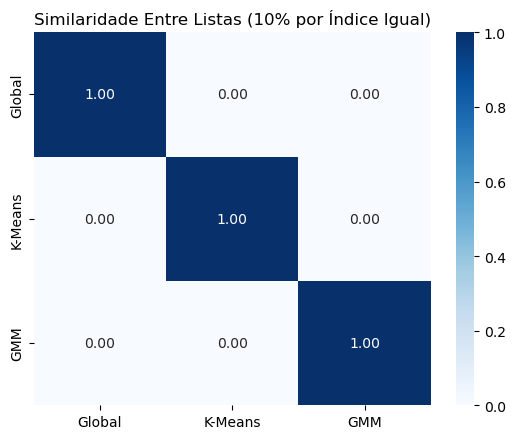

In [75]:
# Vetores de índices Top-10 (ajuste o nome da variável do GMM se estiver diferente no seu notebook)
listas_indices = {
    "Global": top10_global_idx,
    "K-Means": top10_local_idx,
    "GMM": top10_local_idx_gmm,
}

nomes = list(listas_indices.keys())
n = len(nomes)
matriz_sim = np.zeros((n, n), dtype=float)

# Cada índice igual entre duas listas soma 10% (0.10) de similaridade (até 1.00 = 100%)
for i, ni in enumerate(nomes):
    set_i = set(int(x) for x in np.asarray(listas_indices[ni]).tolist())
    for j, nj in enumerate(nomes):
        set_j = set(int(x) for x in np.asarray(listas_indices[nj]).tolist())
        iguais = len(set_i.intersection(set_j))
        matriz_sim[i, j] = iguais * 0.10

df_matriz = pd.DataFrame(matriz_sim, index=nomes, columns=nomes)
print(df_matriz.round(2))

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(
    df_matriz,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0.0,
    vmax=1.0,
)
plt.title("Similaridade Entre Listas (10% por Índice Igual)")
plt.tight_layout()
plt.show()